In [1]:
!pip -q install "transformers>=4.44" "accelerate>=0.33" "bitsandbytes>=0.43" pandas scipy statsmodels openpyxl matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.0 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/Examen_IA2_Tema15'
os.makedirs(BASE, exist_ok=True)
os.chdir(BASE)
print("Trabajando en:", os.getcwd())

Mounted at /content/drive
Trabajando en: /content/drive/MyDrive/Examen_IA2_Tema15


In [3]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # evita la fragmentación de memoria de la GPU
import json, re, math, random, itertools, time, gc
from collections import Counter
import numpy as np
import pandas as pd

# --- Modelo de lenguaje ---
MODEL_ID  = "Qwen/Qwen2.5-7B-Instruct"   # modelo abierto (Zhao et al., 2026; Dao-Duy, 2026)
LOAD_4BIT = True                          # compresión a 4 bits para la GPU T4

# --- Diseño experimental ---
N_RUNS      = 5      # ejecuciones independientes por modo (Kim et al., 2025; Chen, 2026)
K_SAMPLES   = 5      # respuestas candidatas por consulta (autoconsistencia)
TEMP, TOP_P = 0.7, 0.8   # configuración de muestreo por defecto de Qwen2.5
UMBRAL_IC   = 0.60   # consenso mínimo; por debajo se escala al analista
ALPHA       = 0.05   # nivel de significancia
SEED        = 2026   # semilla para reproducibilidad
MAX_NEW_TOKENS = 512 # el prompt oficial de CTIBench pide razonamiento
MAX_SEQS    = 20     # respuestas simultáneas en la GPU T4

# --- Carpetas del proyecto (dentro de Google Drive) ---
for carpeta in ["data/raw", "data/processed", "results", "figures"]:
    os.makedirs(carpeta, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)
print("Configuración lista")
print(f"Modelo: {MODEL_ID} | Ejecuciones: {N_RUNS} | Muestras k: {K_SAMPLES} | Temperatura: {TEMP}")

Configuración lista
Modelo: Qwen/Qwen2.5-7B-Instruct | Ejecuciones: 5 | Muestras k: 5 | Temperatura: 0.7


In [4]:
RUTA_CTI_ATE = "data/raw/cti-ate.tsv"
RUTA_ATTACK  = "data/raw/enterprise-attack-v15.1.json"

for ruta in [RUTA_CTI_ATE, RUTA_ATTACK]:
    if os.path.exists(ruta):
        print(f"✔ {ruta}  ({os.path.getsize(ruta)/1e6:.2f} MB)")
    else:
        print(f"✘ FALTA {ruta}: súbelo a la carpeta data/raw/")

raw = pd.read_csv(RUTA_CTI_ATE, sep="\t")
print("\nFilas y columnas:", raw.shape)
print("\nDescripciones por plataforma:")
print(raw["Platform"].value_counts())
raw[["URL", "Platform", "Description", "GT"]].head()

✔ data/raw/cti-ate.tsv  (0.46 MB)
✔ data/raw/enterprise-attack-v15.1.json  (26.59 MB)

Filas y columnas: (60, 5)

Descripciones por plataforma:
Platform
Enterprise    47
Mobile        13
Name: count, dtype: int64


,URL,Platform,Description,GT
0,https://attack.mitre.org/software/S0066/,Enterprise,3PARA RAT is a remote access tool (RAT) develo...,"T1071, T1573, T1083, T1070"
1,https://attack.mitre.org/software/S0065/,Enterprise,4H RAT is a piece of malware linked to Putter ...,"T1071, T1059, T1573, T1083, T1057, T1082"
2,https://attack.mitre.org/software/S0469/,Enterprise,ABK is a downloader associated with BRONZE BUT...,"T1071, T1059, T1140, T1105, T1027, T1055, T1518"
3,https://attack.mitre.org/software/S1061/,Mobile,AbstractEmu is mobile malware that was first d...,"T1626, T1517, T1437, T1429, T1623, T1533, T140..."
4,https://attack.mitre.org/software/S1028/,Enterprise,Action RAT is a remote access tool developed i...,"T1071, T1059, T1005, T1140, T1083, T1105"


In [5]:
stix = json.load(open(RUTA_ATTACK, encoding="utf-8"))
CATALOGO_TODOS, CATALOGO_VALIDOS, NOMBRES = set(), set(), {}
for objeto in stix["objects"]:
    if objeto.get("type") != "attack-pattern":      # solo técnicas
        continue
    for ref in objeto.get("external_references", []):
        if ref.get("source_name") == "mitre-attack":
            tid = ref["external_id"]
            CATALOGO_TODOS.add(tid)
            if not (objeto.get("revoked", False) or objeto.get("x_mitre_deprecated", False)):
                CATALOGO_VALIDOS.add(tid)
                NOMBRES[tid] = objeto["name"]
TECNICAS_VALIDAS = {t for t in CATALOGO_VALIDOS if "." not in t}

print(f"IDs de técnicas en v15.1 (todos):   {len(CATALOGO_TODOS)}")
print(f"Técnicas principales vigentes:      {len(TECNICAS_VALIDAS)}")
print("¿T1577 (Agent Smith) existe en Enterprise?:", "T1577" in CATALOGO_TODOS)

IDs de técnicas en v15.1 (todos):   780
Técnicas principales vigentes:      202
¿T1577 (Agent Smith) existe en Enterprise?: False


In [6]:
padre = lambda t: t.split(".")[0]          # T1059.001 -> T1059

def a_lista_tecnicas(gt):
    return sorted({padre(x.strip()) for x in str(gt).split(",") if x.strip()})

df = raw[raw["Platform"] == "Enterprise"].copy()
df["gt_set"] = df["GT"].apply(a_lista_tecnicas)
df["gt_en_catalogo"] = df["gt_set"].apply(lambda s: all(t in CATALOGO_TODOS for t in s))
print("Excluidas:", df[~df["gt_en_catalogo"]]["URL"].tolist())
df = df[df["gt_en_catalogo"]].reset_index(drop=True)
df["qid"] = [f"Q{i+1:02d}" for i in range(len(df))]
df["software_id"] = df["URL"].str.extract(r"(S\d{4})")
df.assign(gt_set=df["gt_set"].str.join(", "))[["qid", "software_id", "URL", "Description", "gt_set"]] \
  .to_csv("data/processed/cti_ate_enterprise.csv", index=False, encoding="utf-8")

frecuencias = Counter(t for s in df["gt_set"] for t in s)
print(f"Muestra final: {len(df)} descripciones (Kim: 46) | Técnicas únicas: {len(frecuencias)} (Kim: 77)")

Excluidas: ['https://attack.mitre.org/software/S0440/']
Muestra final: 46 descripciones (Kim: 46) | Técnicas únicas: 77 (Kim: 77)


In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

if not torch.cuda.is_available():
    raise RuntimeError("No hay GPU. Ve a Entorno de ejecución > Cambiar tipo de entorno > T4 GPU")
print("GPU disponible:", torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
config_4bit = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=config_4bit,
                                             device_map="auto").eval()
print("Modelo cargado:", MODEL_ID)
print(f"Memoria de GPU usada: {torch.cuda.memory_allocated()/1e9:.1f} GB")

GPU disponible: Tesla T4


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Modelo cargado: Qwen/Qwen2.5-7B-Instruct
Memoria de GPU usada: 5.9 GB


In [8]:
LOG = "results/log_generaciones.jsonl"
CACHE = {}
if os.path.exists(LOG):                       # retoma lo ya generado (ejecuciones 1 a 3)
    for linea in open(LOG, encoding="utf-8"):
        e = json.loads(linea); CACHE[e["key"]] = e["outputs"]
print("Generaciones ya registradas:", len(CACHE))

SYSTEM = "You are a cyber threat intelligence analyst supporting a Security Operations Center (SOC)."

def _chat(pregunta):
    return tok.apply_chat_template([{"role": "system", "content": SYSTEM},
                                    {"role": "user", "content": pregunta}],
                                   tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def _generar_lote(prompts, temperature, top_p, n, seed):
    torch.manual_seed(seed)
    enc = tok([_chat(p) for p in prompts], return_tensors="pt", padding=True).to(model.device)
    determinista = (temperature == 0)
    out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=not determinista,
                         temperature=None if determinista else temperature,
                         top_p=None if determinista else top_p,
                         num_return_sequences=n, pad_token_id=tok.eos_token_id)
    textos = tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    del out, enc
    return [textos[i*n:(i+1)*n] for i in range(len(prompts))]

def generar(keys, prompts, temperature, top_p, n, seed):
    por_lote = max(1, MAX_SEQS // n)          # n=1 -> 20 consultas por lote; n=5 -> 4 consultas por lote
    pendientes = [i for i, k in enumerate(keys) if k not in CACHE]
    for s in range(0, len(pendientes), por_lote):
        idx = pendientes[s:s+por_lote]
        res = _generar_lote([prompts[i] for i in idx], temperature, top_p, n, seed + s)
        with open(LOG, "a", encoding="utf-8") as f:
            for i, r in zip(idx, res):
                CACHE[keys[i]] = r
                f.write(json.dumps({"key": keys[i], "temperature": temperature, "top_p": top_p,
                                    "n": n, "seed": seed + s, "prompt": prompts[i], "outputs": r},
                                   ensure_ascii=False) + "\n")
        gc.collect(); torch.cuda.empty_cache()
    return [CACHE[k] for k in keys]
print("Motor de generación listo")

Generaciones ya registradas: 456
Motor de generación listo


In [9]:
def prompt_extraccion(fila):
    # Prompt ORIGINAL de CTIBench (Alam et al., 2024) sin la lista de IDs (Kim et al., 2025, p. 179704)
    p = fila["Prompt"]
    p = p.split("**List of All MITRE Enterprise technique IDs**")[0]
    p = p.replace(" MITRE Enterprise IDs are given below as reference.", "")
    return p.strip()

PROMPT_VERIFICACION = (   # verificación reflexiva: componente propio del framework (VI)
    "Below is a cyber threat intelligence report and a list of candidate MITRE ATT&CK technique IDs "
    "proposed for it. For each candidate, decide whether the report contains explicit evidence of that "
    "technique. Reply with one line per candidate using exactly the format 'T####: YES' or 'T####: NO'.\n\n"
    "Report:\n{desc}\n\nCandidates: {cands}"
)
RE_ID        = re.compile(r"\bT\d{4}(?:\.\d{3})?\b")
RE_LINEA_IDS = re.compile(r"^(T?\d{4}(?:\.\d{3})?)([,;\s]+T?\d{4}(?:\.\d{3})?)*$")
RE_ID_FLEX   = re.compile(r"(?<![\d.])T?(\d{4}(?:\.\d{3})?)(?![\d])")

def linea_final(texto):
    lineas = [l for l in texto.strip().splitlines() if l.strip()]
    for linea in reversed(lineas):                       # 1) línea con SOLO IDs
        limpia = re.sub(r"[*`\"'\[\]().]", " ", linea).strip().rstrip(",")
        limpia = re.sub(r"\s+", " ", limpia)
        if limpia and RE_LINEA_IDS.fullmatch(limpia):
            return limpia
    for linea in reversed(lineas):                       # 2) última línea con IDs T####
        if RE_ID.search(linea):
            return linea
    return ""

def ids_emitidos(texto):
    linea = linea_final(texto)
    if RE_LINEA_IDS.fullmatch(linea or "-"):
        return list(dict.fromkeys("T" + m for m in RE_ID_FLEX.findall(linea)))
    return list(dict.fromkeys(RE_ID.findall(linea)))

def decision(texto):
    return sorted({padre(t) for t in ids_emitidos(texto)})

def leer_verificacion(texto, candidatos):
    rechazadas = set()
    for linea in texto.splitlines():
        m = re.search(r"(T\d{4})(?:\.\d{3})?\s*[:\-]\s*(YES|NO)", linea, re.I)
        if m and m.group(2).upper() == "NO":
            rechazadas.add(m.group(1))
    return [c for c in candidatos if c not in rechazadas], sorted(rechazadas & set(candidatos))

df["prompt_ext"] = df.apply(prompt_extraccion, axis=1)
print("Prompts preparados:", len(df))

Prompts preparados: 46


In [10]:
#Ejecución del experimento: modos A0, A, B, C y D (5 ejecuciones)
prompts = df["prompt_ext"].tolist(); descs = df["Description"].tolist(); qids = df["qid"].tolist()
t0 = time.time()

A0 = generar([f"A0|{q}" for q in qids], prompts, 0, 1.0, 1, SEED)
print(f"Referencia A0 lista ({(time.time()-t0)/60:.1f} min)")

registros = []
for run in range(1, N_RUNS + 1):
    seed = SEED + 1000 * run
    # ---- Modo A: LLM directo (preprueba) ----
    outA = generar([f"A|{q}|{run}" for q in qids], prompts, TEMP, TOP_P, 1, seed)
    # ---- Modo B: autoconsistencia (k respuestas + votación por mayoría) ----
    outB = generar([f"B|{q}|{run}" for q in qids], prompts, TEMP, TOP_P, K_SAMPLES, seed + 1)
    infoB = []
    for muestras in outB:
        conjuntos = [tuple(decision(m)) for m in muestras]
        votos = Counter(t for c in conjuntos for t in set(c))
        final = sorted(t for t, v in votos.items() if v > K_SAMPLES / 2)          # más de la mitad
        ic = float(np.mean([votos[t] / K_SAMPLES for t in final])) if final else 0.0
        infoB.append(dict(final=final, ic=ic, unanime=len(set(conjuntos)) == 1,
                          ids_raw=list(dict.fromkeys(i for m in muestras for i in ids_emitidos(m)))))
    # ---- Modo C: + verificación reflexiva ----
    con_cand = [i for i, b in enumerate(infoB) if b["final"]]
    outC = generar([f"C|{qids[i]}|{run}" for i in con_cand],
                   [PROMPT_VERIFICACION.format(desc=descs[i], cands=", ".join(infoB[i]["final"])) for i in con_cand],
                   0, 1.0, 1, seed + 2)
    verif = {i: leer_verificacion(o[0], infoB[i]["final"]) for i, o in zip(con_cand, outC)}

    for i, q in enumerate(qids):
        gt, a_txt, b = sorted(df.at[i, "gt_set"]), outA[i][0], infoB[i]
        c_final, c_desc = verif.get(i, ([], []))
        # ---- Modo D: + validación contra el catálogo MITRE y escalamiento al analista ----
        d_final = [t for t in c_final if t in TECNICAS_VALIDAS]
        bloqueadas = [t for t in c_final if t not in TECNICAS_VALIDAS]
        escalada = (b["ic"] < UMBRAL_IC) or (len(d_final) == 0)
        base = dict(qid=q, software_id=df.at[i, "software_id"], run=run, gt=gt)
        registros += [
            {**base, "modo": "A", "pred": decision(a_txt), "ids_entregados": ids_emitidos(a_txt),
             "ids_generados": ids_emitidos(a_txt)},
            {**base, "modo": "B", "pred": b["final"], "ids_entregados": b["final"], "ids_generados": b["ids_raw"],
             "ic": b["ic"], "unanime": b["unanime"]},
            {**base, "modo": "C", "pred": c_final, "ids_entregados": c_final, "ids_generados": b["ids_raw"],
             "ic": b["ic"], "unanime": b["unanime"], "propuestas": b["final"], "descartadas": c_desc},
            {**base, "modo": "D", "pred": d_final, "ids_entregados": d_final, "ids_generados": b["ids_raw"],
             "ic": b["ic"], "unanime": b["unanime"], "propuestas": b["final"], "descartadas": c_desc,
             "bloqueadas": bloqueadas, "escalada": escalada},
        ]
    print(f"Ejecución {run}/{N_RUNS} lista ({(time.time()-t0)/60:.1f} min acumulados)")

R = pd.DataFrame(registros)
R.to_pickle("results/registros_experimento.pkl")   # respaldo en Drive
print("\nExperimento terminado. Registros:", len(R), "(46 consultas x 4 modos x 5 ejecuciones = 920)")

Referencia A0 lista (0.0 min)
Ejecución 1/5 lista (0.0 min acumulados)
Ejecución 2/5 lista (0.0 min acumulados)
Ejecución 3/5 lista (0.0 min acumulados)
Ejecución 4/5 lista (35.1 min acumulados)
Ejecución 5/5 lista (74.0 min acumulados)

Experimento terminado. Registros: 920 (46 consultas x 4 modos x 5 ejecuciones = 920)


In [11]:
def fila_metricas(r):
    pred, gt = set(r["pred"]), set(r["gt"])
    tp, fp, fn = len(pred & gt), len(pred - gt), len(gt - pred)
    raw_ids = r["ids_entregados"] if isinstance(r["ids_entregados"], list) else []
    inex = [t for t in raw_ids if padre(t) not in CATALOGO_TODOS]
    p = tp / (tp + fp) if pred else 0.0
    rc = tp / (tp + fn) if gt else 0.0
    f1 = 2 * p * rc / (p + rc) if p + rc else 0.0
    return pd.Series(dict(tp=tp, fp=fp, fn=fn, alucinada=int(fp > 0), n_ids=len(raw_ids),
                          n_inexistentes=len(inex), ids_inexistentes=inex, p_q=p, r_q=rc, f1_q=f1))
R = pd.concat([R, R.apply(fila_metricas, axis=1)], axis=1)

def jaccard(a, b):
    a, b = set(a), set(b)
    return 1.0 if not a and not b else len(a & b) / len(a | b)

est = []
for (modo, q), g in R.groupby(["modo", "qid"]):
    preds = [tuple(x) for x in g.sort_values("run")["pred"]]
    js = [jaccard(x, y) for x, y in itertools.combinations(preds, 2)]
    est.append(dict(modo=modo, qid=q, estable=int(len(set(preds)) == 1), jaccard=float(np.mean(js))))
EST = pd.DataFrame(est)
R.head()

,qid,software_id,run,gt,modo,pred,ids_entregados,ids_generados,ic,unanime,...,tp,fp,fn,alucinada,n_ids,n_inexistentes,ids_inexistentes,p_q,r_q,f1_q
0,Q01,S0066,1,"[T1070, T1071, T1083, T1573]",A,"[T1033, T1071, T1083, T1097, T1498]","[T1097, T1071, T1498, T1033, T1083]","[T1097, T1071, T1498, T1033, T1083]",NaN,NaN,...,2,3,2,1,5,0,[],0.4,0.500000,0.444444
1,Q01,S0066,1,"[T1070, T1071, T1083, T1573]",B,"[T1033, T1071]","[T1033, T1071]","[T1204, T1071, T1498, T1033, T1083, T1112, T10...",0.8,False,...,1,1,3,1,2,0,[],0.5,0.250000,0.333333
2,Q01,S0066,1,"[T1070, T1071, T1083, T1573]",C,[],[],"[T1204, T1071, T1498, T1033, T1083, T1112, T10...",0.8,False,...,0,0,4,0,0,0,[],0.0,0.000000,0.000000
3,Q01,S0066,1,"[T1070, T1071, T1083, T1573]",D,[],[],"[T1204, T1071, T1498, T1033, T1083, T1112, T10...",0.8,False,...,0,0,4,0,0,0,[],0.0,0.000000,0.000000
4,Q02,S0065,1,"[T1057, T1059, T1071, T1082, T1083, T1573]",A,"[T1021, T1033, T1071, T1083]","[T1071, T1021, T1083, T1033]","[T1071, T1021, T1083, T1033]",NaN,NaN,...,2,2,4,1,4,0,[],0.5,0.333333,0.400000


In [12]:
def nivel(v, cortes, etiquetas):
    for c, e in zip(cortes, etiquetas):
        if v >= c: return e
    return etiquetas[-1]

def resumen_modo(modo):
    g = R[R.modo == modo]; e = EST[EST.modo == modo]
    por_run = []
    for run, gr in g.groupby("run"):
        tp, fp, fn = gr.tp.sum(), gr.fp.sum(), gr.fn.sum()
        p = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn)
        por_run.append(dict(P=100*p, R=100*rc, F1=2*p*rc/(p+rc) if p + rc else 0.0,
                            TDA=100*gr.alucinada.mean(),
                            TIE=100*gr.n_inexistentes.sum()/max(gr.n_ids.sum(), 1)))
    pr = pd.DataFrame(por_run)
    out = {f"{k}_media": pr[k].mean() for k in pr} | {f"{k}_de": pr[k].std(ddof=1) for k in pr}
    out |= dict(modo=modo, CE=100*e.estable.mean(), J=e.jaccard.mean())
    if modo in "BCD":
        out |= dict(IC=100*g.ic.mean(), TU=100*g.unanime.mean())
    if modo in "CD":
        prop = g.propuestas.apply(len).sum(); desc = g.descartadas.apply(len).sum()
        desc_inc = sum(len(set(d) - set(gt)) for d, gt in zip(g["descartadas"], g["gt"]))
        out |= dict(TD=100*desc/prop if prop else np.nan, EC=100*desc_inc/desc if desc else np.nan)
    if modo == "D":
        gen_inex = sum(len({padre(t) for t in ids if padre(t) not in CATALOGO_TODOS}) for ids in g["ids_generados"])
        fin_inex = sum(len([t for t in p if t not in CATALOGO_TODOS]) for p in g["pred"])
        out |= dict(TB=np.nan if gen_inex == 0 else 100*(gen_inex - fin_inex)/gen_inex,
                    TE=100*g["escalada"].mean())
    return out

RES = pd.DataFrame([resumen_modo(m) for m in "ABCD"]).set_index("modo")
a0 = pd.Series([set(decision(o[0])) for o in A0])
tp0 = sum(len(p & set(g)) for p, g in zip(a0, df.gt_set)); fp0 = sum(len(p - set(g)) for p, g in zip(a0, df.gt_set))
fn0 = sum(len(set(g) - p) for p, g in zip(a0, df.gt_set))
P0, R0 = tp0/(tp0+fp0) if tp0 + fp0 else 0.0, tp0/(tp0+fn0)
print(f"Referencia A0 (temperatura 0, Kim et al., 2025): P={100*P0:.2f}  R={100*R0:.2f}  F1={2*P0*R0/(P0+R0):.4f}")
pd.set_option("display.precision", 2)
RES

Referencia A0 (temperatura 0, Kim et al., 2025): P=25.73  R=15.07  F1=0.1901


,P_media,R_media,F1_media,TDA_media,TIE_media,P_de,R_de,F1_de,TDA_de,TIE_de,CE,J,IC,TU,TD,EC,TB,TE
modo,,,,,,,,,,,,,,,,,,
A,22.87,12.60,0.16,93.91,1.48,2.81,1.42,0.02,3.22,0.57,0.00,0.19,NaN,NaN,NaN,NaN,NaN,NaN
B,36.95,11.30,0.17,61.74,0.94,1.77,1.30,0.02,5.24,0.53,4.35,0.48,59.23,0.0,NaN,NaN,NaN,NaN
C,40.85,8.01,0.13,51.74,0.69,3.51,1.25,0.02,2.83,0.96,10.87,0.48,59.23,0.0,36.02,70.19,NaN,NaN
D,41.43,8.01,0.13,51.30,0.00,3.45,1.25,0.02,2.48,0.00,10.87,0.48,59.23,0.0,36.02,70.19,100.0,26.09


In [13]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import wilcoxon

def prueba_mcnemar(a, d, nombre, hip):
    t = pd.crosstab(pd.Categorical(a, [0, 1]), pd.Categorical(d, [0, 1]), dropna=False).values
    r = mcnemar(t, exact=True)
    return dict(hipotesis=hip, indicador=nombre, prueba="McNemar exacto", n=len(a),
                A=100*np.mean(a), D=100*np.mean(d), estadistico=r.statistic, p_valor=r.pvalue)

def prueba_wilcoxon(a, d, nombre, hip):
    try:
        r = wilcoxon(d, a, zero_method="wilcox"); est, p = r.statistic, r.pvalue
    except ValueError:
        est, p = np.nan, 1.0
    return dict(hipotesis=hip, indicador=nombre, prueba="Wilcoxon", n=len(a),
                A=float(np.mean(a)), D=float(np.mean(d)), estadistico=est, p_valor=p)

ka = R[R.modo == "A"].sort_values(["qid", "run"]); kd = R[R.modo == "D"].sort_values(["qid", "run"])
ea = EST[EST.modo == "A"].sort_values("qid"); ed = EST[EST.modo == "D"].sort_values("qid")
qa = ka.groupby("qid")[["p_q", "f1_q"]].mean(); qd = kd.groupby("qid")[["p_q", "f1_q"]].mean()

PRUEBAS = pd.DataFrame([
    prueba_mcnemar(ea.estable.values, ed.estable.values, "CE (decisión estable)", "H.E. 1"),
    prueba_wilcoxon(ea.jaccard.values, ed.jaccard.values, "J (Jaccard entre ejecuciones)", "H.E. 1"),
    prueba_mcnemar(ka.alucinada.values, kd.alucinada.values, "TDA (decisión alucinada)", "H.E. 2"),
    prueba_wilcoxon(qa.p_q.values, qd.p_q.values, "P (precisión por consulta)", "H.E. 3"),
    prueba_wilcoxon(qa.f1_q.values, qd.f1_q.values, "F1 (por consulta)", "H.E. 3"),
])
PRUEBAS["decision"] = np.where(PRUEBAS.p_valor < ALPHA, "Se rechaza H0", "No se rechaza H0")
PRUEBAS

,hipotesis,indicador,prueba,n,A,D,estadistico,p_valor,decision
0,H.E. 1,CE (decisión estable),McNemar exacto,46,0.00,10.87,0.0,6.25e-02,No se rechaza H0
1,H.E. 1,J (Jaccard entre ejecuciones),Wilcoxon,46,0.19,0.48,106.0,2.06e-06,Se rechaza H0
2,H.E. 2,TDA (decisión alucinada),McNemar exacto,230,93.91,51.30,5.0,7.21e-25,Se rechaza H0
3,H.E. 3,P (precisión por consulta),Wilcoxon,46,0.21,0.32,270.5,3.81e-02,Se rechaza H0
4,H.E. 3,F1 (por consulta),Wilcoxon,46,0.16,0.14,339.0,2.36e-01,No se rechaza H0


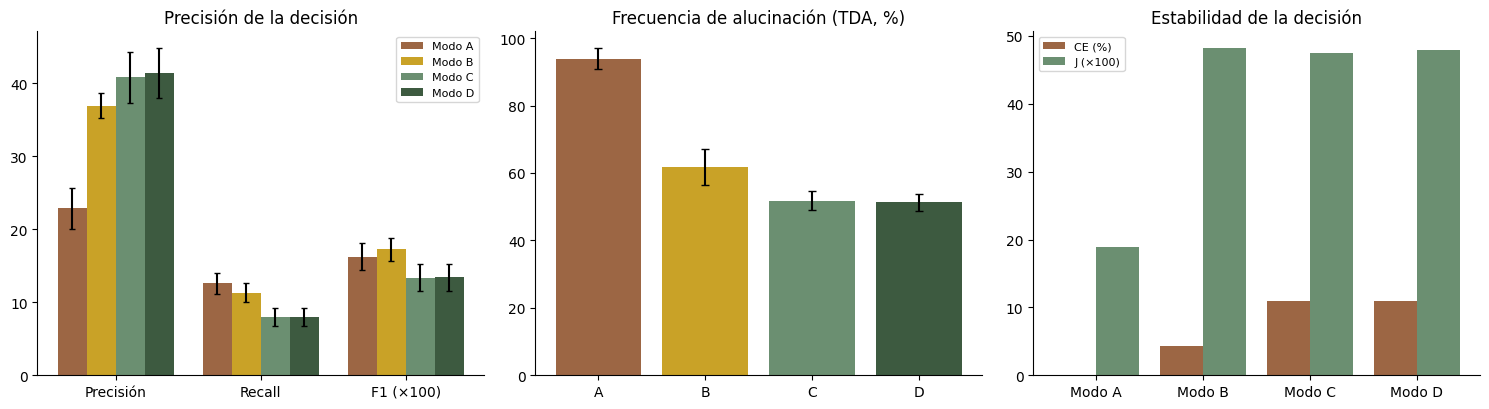

In [14]:
import matplotlib.pyplot as plt
COL = {"A": "#9C6644", "B": "#C9A227", "C": "#6B8F71", "D": "#3D5A40"}
modos = list("ABCD")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(3); w = 0.2
for j, m in enumerate(modos):
    ax[0].bar(x + (j-1.5)*w, [RES.loc[m, "P_media"], RES.loc[m, "R_media"], 100*RES.loc[m, "F1_media"]], w,
              yerr=[RES.loc[m, "P_de"], RES.loc[m, "R_de"], 100*RES.loc[m, "F1_de"]], color=COL[m], label=f"Modo {m}", capsize=2)
ax[0].set_xticks(x, ["Precisión", "Recall", "F1 (×100)"]); ax[0].set_title("Precisión de la decisión"); ax[0].legend(fontsize=8)
ax[1].bar(modos, [RES.loc[m, "TDA_media"] for m in modos], color=[COL[m] for m in modos],
          yerr=[RES.loc[m, "TDA_de"] for m in modos], capsize=3)
ax[1].set_title("Frecuencia de alucinación (TDA, %)")
ax[2].bar(np.arange(4)-0.2, [RES.loc[m, "CE"] for m in modos], 0.4, color="#9C6644", label="CE (%)")
ax[2].bar(np.arange(4)+0.2, [100*RES.loc[m, "J"] for m in modos], 0.4, color="#6B8F71", label="J (×100)")
ax[2].set_xticks(range(4), [f"Modo {m}" for m in modos]); ax[2].set_title("Estabilidad de la decisión"); ax[2].legend(fontsize=8)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/resultados_por_modo.png", dpi=200); plt.show()

In [15]:
NIVELES = {
    "TDA_media": ([25, 10, -1], ["Alta", "Moderada", "Baja"]),
    "TIE_media": ([5, 2, -1], ["Alta", "Moderada", "Baja"]),
    "P_media": ([70, 40, -1], ["Alta", "Media", "Baja"]),
    "F1_media": ([0.70, 0.40, -1], ["Alto", "Medio", "Bajo"]),
    "CE": ([80, 50, -1], ["Alta", "Media", "Baja"]),
    "J": ([0.80, 0.50, -1], ["Alta", "Media", "Baja"]),
    "IC": ([80, 60, -1], ["Alto", "Medio", "Bajo"]),
    "TU": ([70, 40, -1], ["Alta", "Media", "Baja"]),
    "TD": ([20, 10, -1], ["Alta", "Media", "Baja"]),
    "EC": ([80, 60, -1], ["Alta", "Media", "Baja"]),
    "TB": ([95, 80, -1], ["Alta", "Media", "Baja"]),
    "TE": ([35.0001, 20.0001, -1], ["Excesiva", "Moderada", "Adecuada"]),
}
filas = []
for m in modos:
    for k, (cortes, et) in NIVELES.items():
        if k in RES.columns and pd.notna(RES.loc[m, k]):
            v = RES.loc[m, k]; de = RES.loc[m, k.replace("_media", "_de")] if k.endswith("_media") else np.nan
            filas.append(dict(modo=m, indicador=k.replace("_media", ""), valor=round(v, 4),
                              desv_estandar=round(de, 4) if pd.notna(de) else "", nivel=nivel(v, cortes, et)))
RESUMEN = pd.DataFrame(filas)

GEN = pd.DataFrame({"Campo": ["Investigador", "Institución", "Curso", "Fecha de ejecución", "Dataset", "Muestra",
                              "Catálogo de referencia", "Modelo LLM", "Ejecuciones por modo", "Muestras por consulta (k)",
                              "Temperatura / top_p", "Umbral de consenso para escalar", "Nivel de significancia"],
                    "Valor": ["Fabrizzio Felix Arteaga Choccare", "Universidad Nacional de Ingeniería - FIEE",
                              "Inteligencia Artificial II (CBS06) 2026-2", time.strftime("%Y-%m-%d %H:%M"),
                              "CTI-ATE (CTIBench, Alam et al., 2024)", f"{len(df)} descripciones Enterprise",
                              "MITRE ATT&CK Enterprise v15.1 (STIX 2.1)", MODEL_ID, N_RUNS, K_SAMPLES,
                              f"{TEMP} / {TOP_P}", UMBRAL_IC, ALPHA]})
GEN = pd.concat([GEN, pd.DataFrame({"Campo": ["Referencia A0 (temperatura 0, Kim et al., 2025): P / R / F1"],
                                    "Valor": [f"{100*P0:.2f} % / {100*R0:.2f} % / {2*P0*R0/(P0+R0) if P0+R0 else 0:.4f}"]})])
REG = R[["qid", "software_id", "modo", "run", "gt", "pred", "tp", "fp", "fn", "alucinada", "n_ids",
         "n_inexistentes", "ids_inexistentes", "ic", "unanime", "descartadas", "bloqueadas", "escalada"]].copy()
for c in ["gt", "pred", "ids_inexistentes", "descartadas", "bloqueadas"]:
    REG[c] = REG[c].apply(lambda v: ", ".join(v) if isinstance(v, list) else "")

with pd.ExcelWriter("results/Ficha_Registro_Observacion.xlsx", engine="openpyxl") as xw:
    GEN.to_excel(xw, sheet_name="1_Datos_generales", index=False)
    REG.to_excel(xw, sheet_name="2_Registro_por_consulta", index=False)
    RESUMEN.to_excel(xw, sheet_name="3_Resumen_por_modo", index=False)
    PRUEBAS.to_excel(xw, sheet_name="4_Pruebas_hipotesis", index=False)
    for ws in xw.book.worksheets:
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(45, max(12, max(len(str(c.value or "")) for c in col) + 2))
        ws.freeze_panes = "A2"

R.to_csv("results/registro_decisiones.csv", index=False, encoding="utf-8")
RES.to_csv("results/resumen_por_modo.csv", encoding="utf-8")
PRUEBAS.to_csv("results/pruebas_hipotesis.csv", index=False, encoding="utf-8")
print("Archivos generados en results/ y figures/")
RESUMEN.pivot(index="indicador", columns="modo", values="nivel")

Archivos generados en results/ y figures/


modo,A,B,C,D
indicador,,,,
CE,Baja,Baja,Baja,Baja
EC,NaN,NaN,Media,Media
F1,Bajo,Bajo,Bajo,Bajo
IC,NaN,Bajo,Bajo,Bajo
J,Baja,Baja,Baja,Baja
P,Baja,Baja,Media,Media
TB,NaN,NaN,NaN,Alta
TD,NaN,NaN,Alta,Alta
TDA,Alta,Alta,Alta,Alta
